In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Week 1

### Question 1a

Analytical:
$$\frac{dp}{dz} = -\frac{gp}{R_dT}$$
$$\frac{dp}{dz} = -\frac{gp}{R_d(T_{sfc}+\gamma z)}$$
$$p(z) = p_0 \left(1 + \frac{\gamma z}{T_{sfc}}\right)^{-\frac{g}{R_d\gamma}}$$

Discrete:
$$p_{i+1} = p_i - \frac{gp_i}{R_dT_{\frac{1}{2}}}\Delta z$$

In [2]:
def p_numerical(z,g = 9.81, Rd = 287.05, Tsfc = 293, gamma = -0.006, p0 = 101800):
    """
    """
    dz = z[1] - z[0]
    # print(fr'\Delta z = ',dz)
    p = np.zeros(len(z))
    p[0] = p0 #pa

    for i in range(len(p)-1):
        T_lower = Tsfc + gamma * z[i]
        T_upper = Tsfc + gamma * z[i+1] 
        T_12 = (T_lower + T_upper) / 2 
        p_new = p[i] - (g * p[i] * dz) / (Rd * T_12)

        p[i+1] = p_new

    return p

def p_analytical(z, g = 9.81, Rd = 287.05, Tsfc = 293, gamma = -0.006, p0 = 101800):

    T = Tsfc + gamma * z

    p = p0 * (T / Tsfc) ** ((-g) / (Rd * gamma))

    return p

<function matplotlib.pyplot.show(close=None, block=None)>

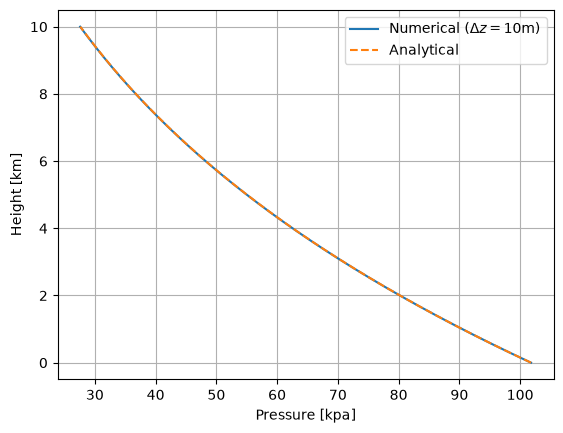

In [3]:
n = 1000
z = np.linspace(0,10000,n+1)
p_num = p_numerical(z)

p_an = p_analytical(z)


plt.plot(p_num / 1000,z/1000, label = fr'Numerical ($\Delta z = {int(z[1]-z[0])}$m)')
plt.plot(p_an / 1000, z / 1000, label = 'Analytical', linestyle = 'dashed')
plt.ylabel('Height [km]')
plt.xlabel('Pressure [kpa]')
# plt.title('Pressure at height for dry atmosphere')

plt.legend()
plt.grid()
plt.savefig('Pressure at height', dpi = 300)
plt.show

### Question 1b

In [4]:
def density(p,z, Rd = 287.05, Tsfc = 293, gamma = -0.006):

    rho = np.zeros(len(p))

    for i in range(len(z)):
        rho[i] = p[i] / (Rd * (Tsfc + gamma * z[i]))

    return rho

surface density: 1.210km/m3
Density is half of surface at height 6.7km


<function matplotlib.pyplot.show(close=None, block=None)>

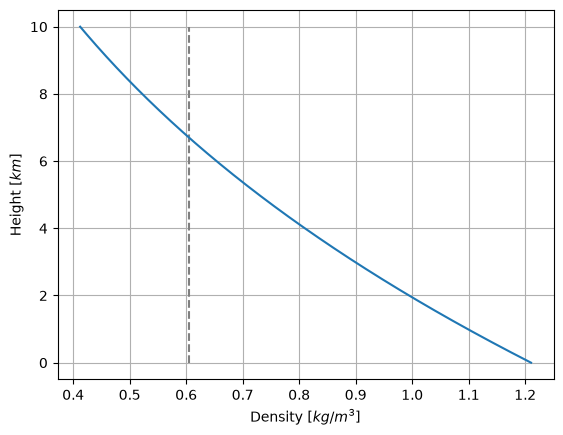

In [5]:
rho = density(p_num,z)

rho_sfc = rho[0]
print(f"surface density: {rho_sfc:.3f}km/m3")

i = 0
while i < len(rho) and rho[i] >= (rho_sfc / 2):
    i += 1
half_rho_z = z[i] if i < len(rho) else None

print(f'Density is half of surface at height {half_rho_z / 1000}km')

plt.plot((rho_sfc / 2) * np.ones(len(rho)), z / 1000, color = 'gray', linestyle = 'dashed')

plt.plot(rho, z / 1000)

plt.xlabel('Density [$kg/m^3$]')
plt.ylabel('Height [$km$]')
# plt.title('Dry air density')
plt.grid()
plt.savefig('Dry air density', dpi = 300)
plt.show

### Question 1c

In [6]:
def vapor_q(p,z, RH, Tsfc = 293, gamma = -0.006, Rd = 287.05, Rv = 461.50):

    T = Tsfc + gamma * z

    e_sat = 610.78 * np.exp((17.2694 * (T - 273.16)) /  (T - 35.86))

    e_vap = RH * e_sat

    q_vap = e_vap / (((Rv / Rd) * (p - e_vap)) + e_vap)

    q_vap = q_vap * 1000 # convert to g/kg

    return q_vap

For Tsfc = 271, q_vap at 5km is 0.369 g/kg
For Tsfc = 303, q_vap at 5km is 5.480 g/kg


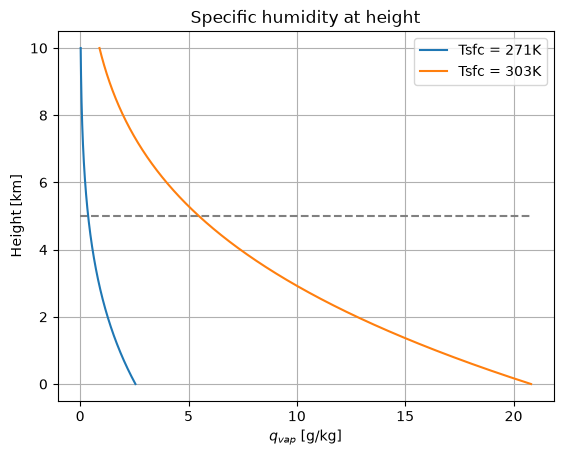

In [7]:
q_vap1 = vapor_q(p_num, z, 0.8, Tsfc = 271)
q_vap2 = vapor_q(p_num, z, 0.8, Tsfc = 303)

plt.plot(np.linspace(0, max(q_vap2), len(q_vap2)), 5 * np.ones(len(q_vap1)), color = 'gray', linestyle = 'dashed')

plt.plot(q_vap1, z / 1000, label = 'Tsfc = 271K')
plt.plot(q_vap2, z / 1000, label = 'Tsfc = 303K')

print(f'For Tsfc = 271, q_vap at 5km is {q_vap1[int(len(z) / 2)]:.3f} g/kg')
print(f'For Tsfc = 303, q_vap at 5km is {q_vap2[int(len(z) / 2)]:.3f} g/kg')

plt.xlabel('$q_{vap}$ [g/kg]')
plt.ylabel('Height [km]')
plt.title('Specific humidity at height')
plt.legend()
plt.grid()
plt.show()

### Question 1d

In [8]:
def calculate_WVP(z,
                  RH = 0.8, 
                  Tsfc = 293, 
                  gamma = -0.006, 
                  Rd = 287.05, 
                  Rv = 461.50, 
                  p0 = 101800, 
                  g = 9.81
                  ):
    """
    Compute Water Vapor Path 
    """

    dz = z[1] - z[0]

    # Calculate pressure
    p = p_numerical(z, Tsfc = Tsfc)

    #Calculate density
    rho= density(p,z, Tsfc = Tsfc)

    # Calculate q_v
    q_vap = vapor_q(p,z, RH = RH, Tsfc = Tsfc)

    # Water pavor per layer
    wv = rho * q_vap

    return np.sum(wv * dz)


Minimum WVP: 2854.688 kg m^-2
Maximum WVP: 99434.569 kg m^-2


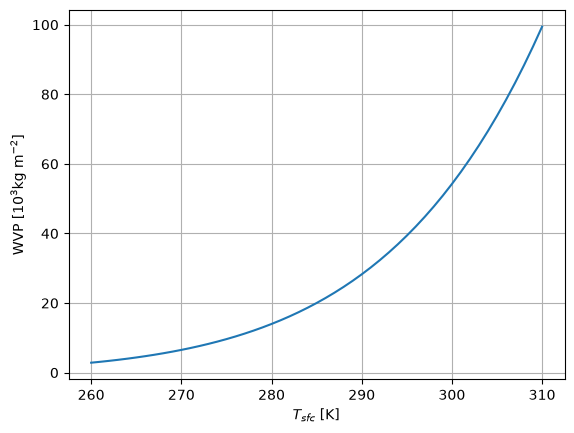

[ 256.38155689  276.88643304  298.82208847  322.27300323  347.32767348
  374.07875208  402.62319239  433.06239513  465.50235866  500.05383262
  536.83247506  575.95901322  617.55940814  661.76502319  708.71279674
  758.54541925  811.41151484  867.46582784  926.86941434  989.78983932
 1056.40137953 1126.88523253 1201.42973249 1280.23057294 1363.49103724
 1451.42223724 1544.24336063 1642.18192796 1745.47405972 1854.36475456
 1969.10817931 2089.96797203 2217.21755875 2351.14048545 2492.0307661
 2640.19324843 2795.94399862 2959.61070657 3131.5331135  3312.06346356
 3501.5669815  3700.42237865 3909.02238926 4127.77434002 4357.10075523
 4597.44000067 4849.24696941 5112.99381277 5389.17072048 5678.28675385]


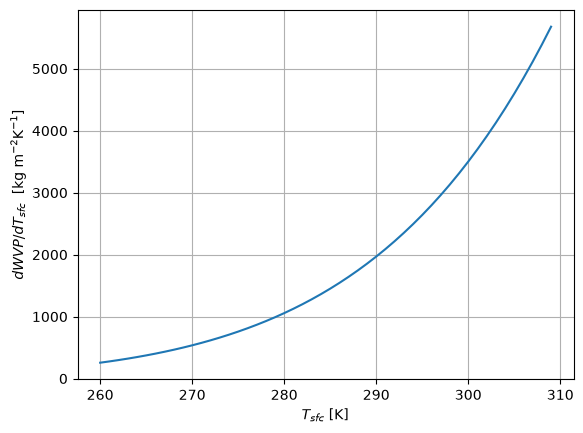

In [9]:
n = 1000
z = np.linspace(0,10000,n+1)

Tsfc_range = np.linspace(260, 310, 51)

wvp_arr = np.zeros(len(Tsfc_range))
for index, i in enumerate(Tsfc_range):
    wvp_arr[index] = calculate_WVP(z,Tsfc = i)

print(f'Minimum WVP: {np.min(wvp_arr):.3f} kg m^-2')
print(f'Maximum WVP: {np.max(wvp_arr):.3f} kg m^-2')
plt.plot(Tsfc_range, wvp_arr / 1000)
plt.xlabel('$T_{sfc}$ [K]')
plt.ylabel('WVP [$10^{3}\\text{kg m}^{-2}$]')
plt.grid()
plt.show()

# Calculate dWVP/dTsfc

#-------------------------
# Not sure if correct
#-------------------------

dwvp = np.zeros(len(wvp_arr) - 1)
for i in range(len(wvp_arr)-1):
    dwvp[i] = wvp_arr[i+1] - wvp_arr[i]

dWVPdt = dwvp / (Tsfc_range[1] - Tsfc_range[0])
print(dWVPdt)

plt.plot(Tsfc_range[:-1], dWVPdt)
plt.xlabel('$T_{sfc}$ [K]')
plt.ylabel('$dWVP / dT_{sfc}$  $[\\text{kg m}^{-2}\\text{K}^{-1}]$')
plt.grid()


### Question 1e